In [56]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import datasets
import warnings
warnings.filterwarnings('ignore')
%matplotlib inline

# **Data exploring**

In [57]:
sns.set()

In [58]:
data=datasets.load_iris()
data.keys()

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])

In [59]:

print(data['feature_names'])
print(data['target'])


['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2]


In [60]:
df=pd.DataFrame(data['data'],columns=data['feature_names'],index=range(1, len(data['data'])+1))
df['target']=data['target']
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
1,5.1,3.5,1.4,0.2,0
2,4.9,3.0,1.4,0.2,0
3,4.7,3.2,1.3,0.2,0
4,4.6,3.1,1.5,0.2,0
5,5.0,3.6,1.4,0.2,0


In [61]:
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


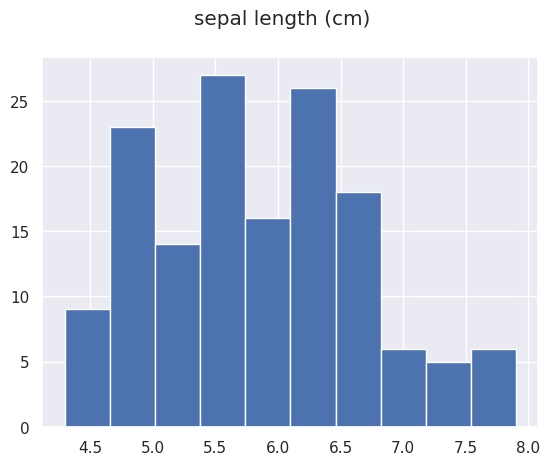

In [62]:
labl='sepal length (cm)'
df[labl].hist()
plt.suptitle(labl)
plt.show()

Give numerical values names for better understanding

In [63]:
df['flower_ name']= df['target'].map({0:'setosa',1:'versicolor',2:'virginica'})
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,flower_ name
1,5.1,3.5,1.4,0.2,0,setosa
2,4.9,3.0,1.4,0.2,0,setosa
3,4.7,3.2,1.3,0.2,0,setosa
4,4.6,3.1,1.5,0.2,0,setosa
5,5.0,3.6,1.4,0.2,0,setosa


In [64]:
sepal_length= df['sepal length (cm)']
sepal_width = df['sepal width (cm)']
petal_length = df['petal length (cm)']
petal_width = df['petal width (cm)']


understanding  each feature relationship with the target  by using relplot from sns for visualization

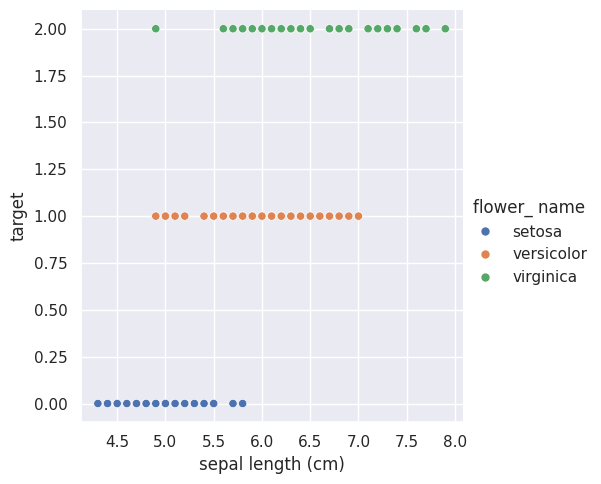

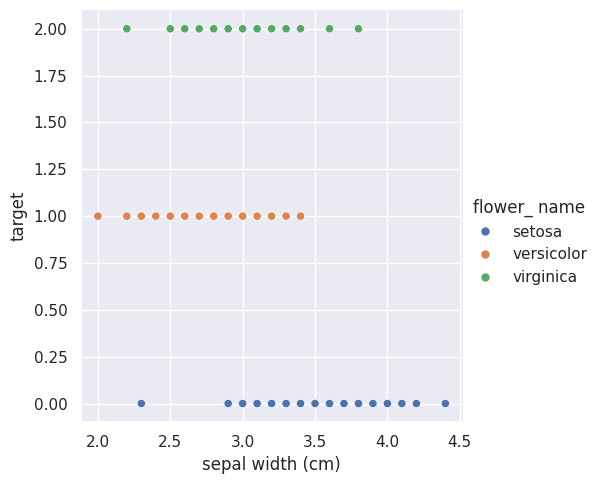

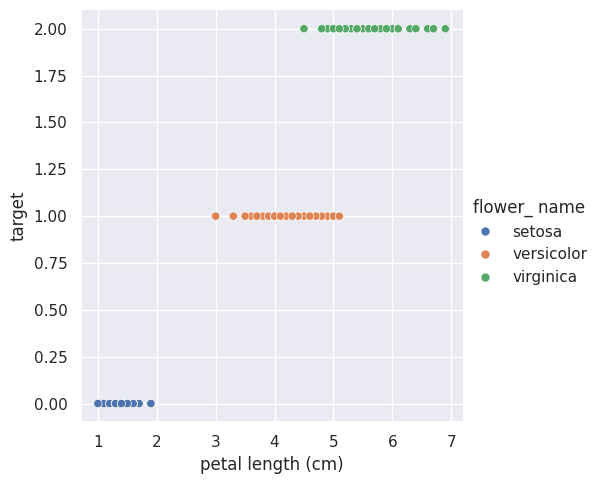

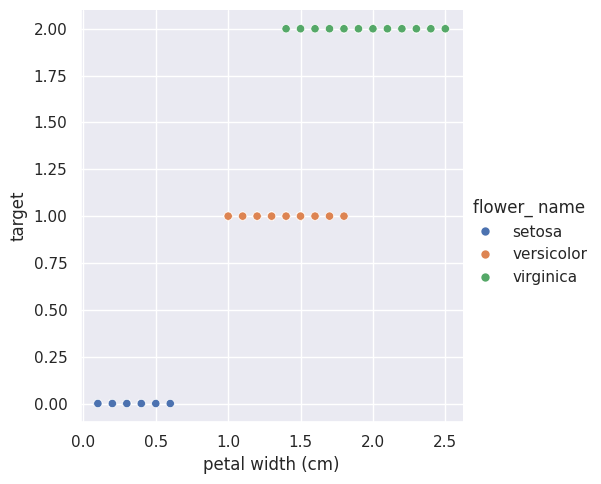

In [65]:
df['flower_ name'] = df['target'].map({0:'setosa',1:'versicolor',2:'virginica'})
print(sns.relplot(x=sepal_length ,y='target', hue='flower_ name', data =df ))
print(sns.relplot(x=sepal_width,y='target', hue='flower_ name', data =df ))
print(sns.relplot(x=petal_length,y='target', hue='flower_ name', data =df ))
print(sns.relplot(x=petal_width,y='target', hue='flower_ name', data =df ))

using pairplot to compare each column with the other (feature)

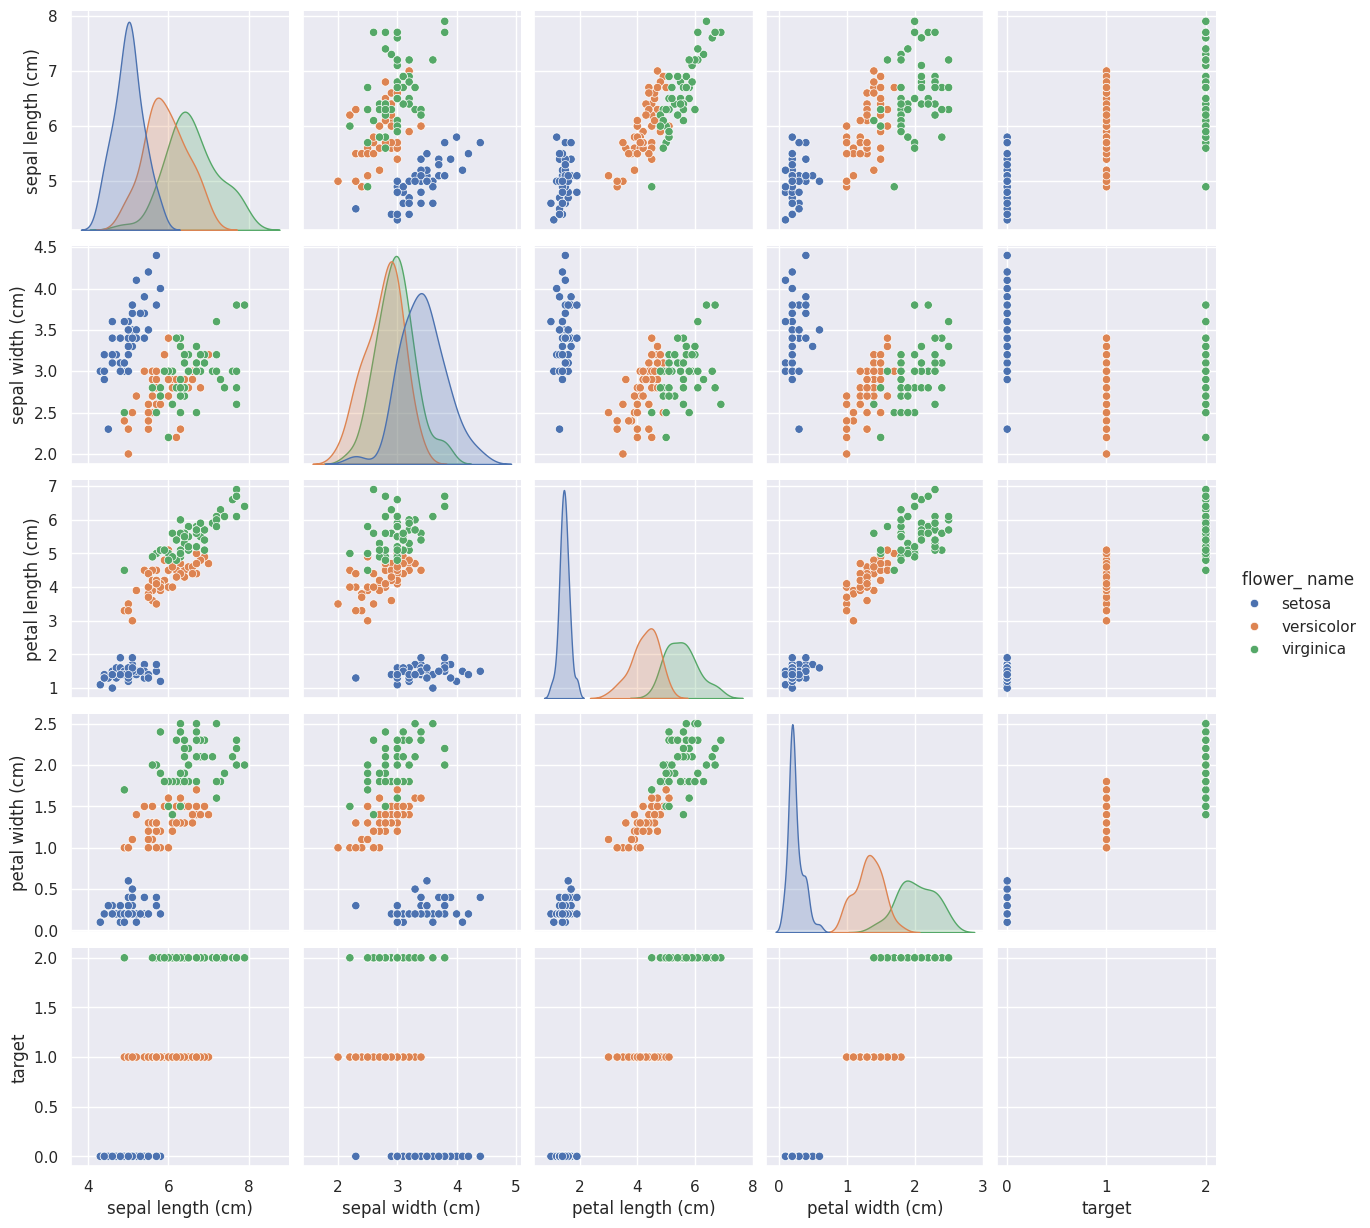

In [66]:
sns.pairplot(df, hue= 'flower_ name')

# *Model training *
 I implemented the model using Linear Regression from scikit-learn
 and KNN manually from scratch.

 # Model training cycle:
 1. Split the data into training and testing sets.
 2. Fit (train) the model using the training data.
 3. Predict labels for the testing data.
 4. Compare predictions with actual labels to measure accuracy.
 5. Optimize the model by changing parameters, such as k in KNN.




In [67]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

X=df.drop(['target','flower_ name'],axis=1)
y=df['target']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2)


model= LogisticRegression(random_state=0)
model.fit(X_train,y_train)

LogisticRegression(random_state=0)

In [68]:
y_prediction=model.predict(X_test)
model.score(X_test,y_test)

0.9666666666666667

In [69]:
np.array(y_prediction==y_test)

array([ True,  True,  True,  True,  True,  True,  True,  True, False,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True])

In [70]:
from sklearn.model_selection import cross_val_score

accuracies=cross_val_score(model,cv=5,X=X_train,y=y_train)
print(accuracies)

[0.91666667 0.91666667 1.         0.95833333 1.        ]


In [71]:
np.mean(accuracies)

np.float64(0.9583333333333333)

cross_val_score  → "How well did the model perform?"

cross_val_predict → "What did the model predict?"


In [72]:
from sklearn.model_selection import cross_val_predict
y_prediction=cross_val_predict(model,X_train,y_train,cv=3)

correct_prediction= (y_prediction==y_train)
df=X_train.copy() # Initialize df with all of X_train
display(df)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
129,6.4,2.8,5.6,2.1
88,6.3,2.3,4.4,1.3
109,6.7,2.5,5.8,1.8
21,5.4,3.4,1.7,0.2
108,7.3,2.9,6.3,1.8
...,...,...,...,...
147,6.3,2.5,5.0,1.9
32,5.4,3.4,1.5,0.4
4,4.6,3.1,1.5,0.2
5,5.0,3.6,1.4,0.2


In [73]:
flase_prediction= ~correct_prediction
df_flase_prediction=X_train[flase_prediction]
df_flase_prediction

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
84,6.0,2.7,5.1,1.6
78,6.7,3.0,5.0,1.7
139,6.0,3.0,4.8,1.8
134,6.3,2.8,5.1,1.5


In [74]:
df['correct prediction'] = correct_prediction
df['prediction_result'] = y_prediction
df['prediction_result'] = df['prediction_result'].map({0:'setosa',1:'versicolor',2:'virginica'})
df

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),correct prediction,prediction_result
129,6.4,2.8,5.6,2.1,True,virginica
88,6.3,2.3,4.4,1.3,True,versicolor
109,6.7,2.5,5.8,1.8,True,virginica
21,5.4,3.4,1.7,0.2,True,setosa
108,7.3,2.9,6.3,1.8,True,virginica
...,...,...,...,...,...,...
147,6.3,2.5,5.0,1.9,True,virginica
32,5.4,3.4,1.5,0.4,True,setosa
4,4.6,3.1,1.5,0.2,True,setosa
5,5.0,3.6,1.4,0.2,True,setosa


# Manual KNN implementation:
 For simpler practice, you can use the KNN model directly from the
 scikit-learn library. I implemented it manually to gain a clearer
 understanding of how the KNN algorithm works.

In [29]:
from collections import Counter
from sklearn.model_selection import train_test_split
import numpy as np

class KNN:
    def __init__(self,k=3):
        self.k = k
        self.X_train = None
        self.y_train = None
        self.predictions =[]

    def split (self,df, target):

        X=df.drop(target,axis=1)
        y=df[target]

        X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state= 6) # random state is used to get the same split each time
        return  X_train, X_test, y_train, y_test

    def fit(self,X_train,y_train):

        self.X_train = np.array(X_train)
        self.y_train = np.array(y_train )


    def predict(self, X_test):
        X_test = np.array(X_test)
        self.predictions = []   # reset old predictions

        for test_point in X_test:
            distances = []


            for train_point in self.X_train:
                distance = np.sqrt(np.sum((train_point - test_point) ** 2))
                distances.append(distance)


            nearest_indices = np.argsort(distances)[:self.k]
            nearest_labels = self.y_train[nearest_indices]
            common = Counter(nearest_labels).most_common(1)[0][0]

            self.predictions.append(common)

        return np.array(self.predictions)



    def accuracy(self, y_test):
        # Ensure y_test is a numpy array for consistent comparison
        y_test_array = y_test.to_numpy() if hasattr(y_test, 'to_numpy') else np.array(y_test)

        if self. predictions is not None:
           Accuracy_score = np.sum(y_test_array == self.predictions) / len(y_test_array)
           return "Accuracy: {:.2%}".format(Accuracy_score)
        else:
           return 'predictions is none '


In [32]:
from sklearn import datasets
import pandas as pd

data=datasets.load_iris()

df=pd.DataFrame(data['data'],columns=data['feature_names'],index=range(1, len(data['data'])+1))
df['target']=data['target']

knn=KNN(3)
X_train, X_test, y_train, y_test=knn.split(df,'target')
knn.fit(X_train, y_train)

prediction=knn.predict(X_test)
actual = y_test.to_numpy()
labels = {0: 'setosa', 1: 'versicolor', 2: 'virginica'}


comparison = pd.DataFrame({
    "Actual": pd.Series(actual ).map(labels),
    "Predicted": pd.Series(prediction).map(labels)
})
print(comparison)


knn.accuracy(y_test)





        Actual   Predicted
0       setosa      setosa
1    virginica   virginica
2       setosa      setosa
3       setosa      setosa
4    virginica   virginica
5   versicolor  versicolor
6    virginica   virginica
7       setosa      setosa
8    virginica   virginica
9   versicolor  versicolor
10   virginica   virginica
11  versicolor  versicolor
12   virginica   virginica
13   virginica   virginica
14  versicolor  versicolor
15   virginica  versicolor
16   virginica   virginica
17  versicolor  versicolor
18  versicolor  versicolor
19      setosa      setosa
20      setosa      setosa
21   virginica   virginica
22      setosa      setosa
23      setosa      setosa
24  versicolor  versicolor
25  versicolor   virginica
26  versicolor  versicolor
27   virginica   virginica
28      setosa      setosa
29  versicolor  versicolor


'Accuracy: 93.33%'